Single allele groupped structue models.

In [67]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import logomaker
import sys
import seaborn as sns
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [68]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu

DATA_PATH = f'{DATA_PATH_BASE}/core_identification_Tom/per_length_per_kfold_split/' # work laptop
TARGET_PATH_TO_RESULTS = "experiment_results/core_identification_Tom/" #!CHANGE for bwv!

In [69]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
# per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
# per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['H2-AA*s/AB*s',
 'H2-AA*u/AB*u',
 'H2-AA*q/AB*q',
 'H2-AA*k/AB*k',
 'H2-AA*d/AB*d',
 'H2-EA*d/EB*d',
 'H2-AA*b/AB*b']

In [70]:
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

In [71]:
ALLELES

['H2-AA*s/AB*s',
 'H2-AA*u/AB*u',
 'H2-AA*q/AB*q',
 'H2-AA*k/AB*k',
 'H2-AA*d/AB*d',
 'H2-EA*d/EB*d',
 'H2-AA*b/AB*b']

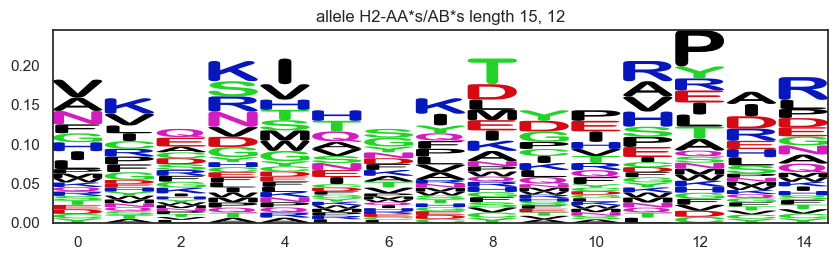

In [72]:
target_allele = ALLELES[0]
target_length = 15

binders_array = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(binders_array, f"allele {target_allele} length {target_length}")

In [78]:
{tl: len(data) for tl, data  in per_allele_per_kfold_per_length_binders_train[ALLELES[-1]][0].items()}

{8: 353,
 9: 454,
 10: 452,
 11: 449,
 12: 530,
 13: 677,
 14: 984,
 15: 1392,
 16: 1268,
 17: 941,
 18: 584,
 19: 412,
 20: 296,
 21: 208,
 22: 144,
 23: 104,
 24: 88,
 25: 60,
 26: 45,
 27: 43,
 28: 28,
 29: 24,
 30: 19}

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations

In [7]:
# combination_size = len(ALLELES)
# ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
#                   ])
# ALLELES = sorted([ 'HLA-A*03:01'])

# ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DPA1*01:03-DPB1*04:01'])

# sorted(['HLA-DRB1*01:01','HLA-DRB1*04:01','HLA-DPA1*01:03/DPB1*04:01','HLA-DRB1*03:01','HLA-DRB1*15:01', 'HLA-DRB3*01:01',
#  'HLA-DRB5*01:01'])

# ALLELES = sorted([#'HLA-DQA1*05:01/DQB1*02:01', 
#                   'HLA-DPA1*02:02/DPB1*05:01'
#                  ])

combination_size = 1

TOTAL_SPLITS = 5
NUM_RUNS = 10
USE_WEIGHTS = False
TARGET_LENGTHS=  [12, 13,14, 15, 16,17, 18]

# TARGET_LENGTHS= [15]
# TARGET_LENGTHS= [9]
check_peptides = True

In [8]:
per_allele_per_kfold_per_length_binders_train.keys()

dict_keys(['H2-AA*s/AB*s', 'H2-AA*u/AB*u', 'H2-AA*q/AB*q', 'H2-AA*k/AB*k', 'H2-AA*d/AB*d', 'H2-EA*d/EB*d', 'H2-AA*b/AB*b'])

## Motif for train data

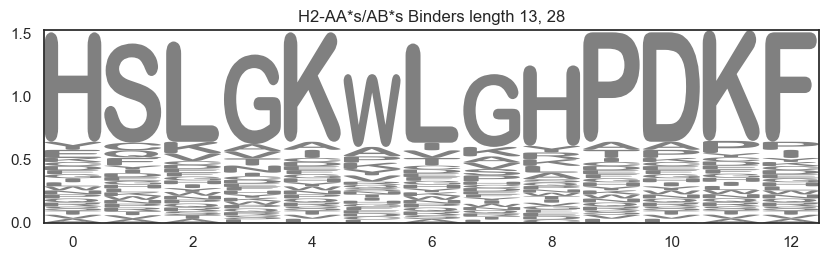

In [9]:

target_length = 13
peptides = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(peptides, f"{ target_allele} Binders length {target_length}")

# Transform data

In [10]:
for allele_name in ALLELES:
    for split_num in range(TOTAL_SPLITS):
        new_dict = dict()
        for tl in TARGET_LENGTHS:
            if tl in per_allele_per_kfold_per_length_binders_train[allele_name][split_num]:
                new_dict[tl] = per_allele_per_kfold_per_length_binders_train[allele_name][split_num][tl]
        per_allele_per_kfold_per_length_binders_train[allele_name][split_num] = new_dict

In [11]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test


if check_peptides:
    transform_dicts=None

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS,
    list_of_transform_dicts=None
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

H2-AA*s/AB*s
Length 16: H2-AA*s/AB*s - 4 
Length 13: H2-AA*s/AB*s - 28 
Length 15: H2-AA*s/AB*s - 12 
H2-AA*u/AB*u
Length 13: H2-AA*u/AB*u - 10 
Length 14: H2-AA*u/AB*u - 7 
Length 15: H2-AA*u/AB*u - 8 
H2-AA*q/AB*q
Length 15: H2-AA*q/AB*q - 4 
H2-AA*k/AB*k
Length 16: H2-AA*k/AB*k - 8 
Length 13: H2-AA*k/AB*k - 20 
Length 14: H2-AA*k/AB*k - 9 
Length 15: H2-AA*k/AB*k - 15 
H2-AA*d/AB*d
Length 16: H2-AA*d/AB*d - 38 
Length 17: H2-AA*d/AB*d - 35 
Length 18: H2-AA*d/AB*d - 24 
Length 12: H2-AA*d/AB*d - 6 
Length 13: H2-AA*d/AB*d - 14 
Length 14: H2-AA*d/AB*d - 21 
Length 15: H2-AA*d/AB*d - 76 
H2-EA*d/EB*d
Length 13: H2-EA*d/EB*d - 8 
Length 14: H2-EA*d/EB*d - 11 
Length 15: H2-EA*d/EB*d - 15 
H2-AA*b/AB*b
Length 16: H2-AA*b/AB*b - 1268 
Length 17: H2-AA*b/AB*b - 941 
Length 18: H2-AA*b/AB*b - 584 
Length 12: H2-AA*b/AB*b - 530 
Length 13: H2-AA*b/AB*b - 677 
Length 14: H2-AA*b/AB*b - 984 
Length 15: H2-AA*b/AB*b - 1392 


In [12]:
ALLELES

['H2-AA*s/AB*s',
 'H2-AA*u/AB*u',
 'H2-AA*q/AB*q',
 'H2-AA*k/AB*k',
 'H2-AA*d/AB*d',
 'H2-EA*d/EB*d',
 'H2-AA*b/AB*b']

## 2.2 Calculate counts of initial data (will be used to calculate weights further)

In [13]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [14]:
count_df_train.index.levels

FrozenList([['H2-AA*b/AB*b', 'H2-AA*d/AB*d', 'H2-AA*k/AB*k', 'H2-AA*q/AB*q', 'H2-AA*s/AB*s', 'H2-AA*u/AB*u', 'H2-EA*d/EB*d'], [0, 1, 2, 3, 4], [15]])

In [15]:
count_df_train

cnt
allele       split length      
H2-AA*b/AB*b 0     15      1392
             1     15      1392
             2     15      1392
             3     15      1392
             4     15      1392
H2-AA*d/AB*d 0     15        76
             1     15        77
             2     15        77
             3     15        77
             4     15        77
H2-AA*k/AB*k 0     15        15
             1     15        15
             2     15        15
             3     15        15
             4     15        16
H2-AA*q/AB*q 0     15         4
             1     15         5
             2     15         5
             3     15         5
             4     15         5
H2-AA*s/AB*s 0     15        12
             1     15        13
             2     15        13
             3     15        13
             4     15        13
H2-AA*u/AB*u 0     15         8
             1     15         9
             2     15         9
             3     15         9
             4     15         9
H2-EA*d/EB*d 0     15        15
             1     15        15
             2     15        15
             3     15        15
             4     15        16

## 2.3 Weights for data based on counts

In [16]:
# something with weights, not working with missing lengths

sub_count_df_train = count_df_train.loc[(count_df_train.index.get_level_values('split') == 0) &
                                        (count_df_train.index.get_level_values('allele').isin(ALLELES)) &
                                        (count_df_train.index.get_level_values('length').isin(TARGET_LENGTHS))]
per_allele_per_kfold_per_length_weights = calculate_weights_based_on_length_counts(count_df_train,
                                                                                   selected_alleles=ALLELES,
                                                                                   total_splits=TOTAL_SPLITS,
                                                                                   selected_lengths=TARGET_LENGTHS,
                                                                                   use_weights=USE_WEIGHTS)

Total data length for split 0 is 12
Weights for lentgh 15 are {'H2-AA*s/AB*s': 1}
Total data length for split 1 is 12
Weights for lentgh 15 are {'H2-AA*s/AB*s': 1}
Total data length for split 2 is 12
Weights for lentgh 15 are {'H2-AA*s/AB*s': 1}
Total data length for split 3 is 12
Weights for lentgh 15 are {'H2-AA*s/AB*s': 1}
Total data length for split 4 is 12
Weights for lentgh 15 are {'H2-AA*s/AB*s': 1}
Total data length for split 0 is 8
Weights for lentgh 15 are {'H2-AA*u/AB*u': 1}
Total data length for split 1 is 8
Weights for lentgh 15 are {'H2-AA*u/AB*u': 1}
Total data length for split 2 is 8
Weights for lentgh 15 are {'H2-AA*u/AB*u': 1}
Total data length for split 3 is 8
Weights for lentgh 15 are {'H2-AA*u/AB*u': 1}
Total data length for split 4 is 8
Weights for lentgh 15 are {'H2-AA*u/AB*u': 1}
Total data length for split 0 is 4
Weights for lentgh 15 are {'H2-AA*q/AB*q': 1}
Total data length for split 1 is 4
Weights for lentgh 15 are {'H2-AA*q/AB*q': 1}
Total data length for s

In [17]:
per_allele_per_kfold_per_length_weights = {
allele_name: {
    fold_num: {
        cur_length: [1 for peptide in peptides]
        for cur_length, peptides in per_length_data.items()
    }
    for fold_num, per_length_data in per_fold_per_length_data.items()
}
    for allele_name, per_fold_per_length_data in per_allele_per_kfold_per_length_binders_train_old.items()

}

## Transform to properties

# 2. Train HMMS
## 2.1 Code for HMM
### 2.1.1 Training code

In [18]:
from hmm_logic_methods import train_model, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model_joiners_and_cycles



## 2.2 Train
### 2.2.1 Define treshold

In [19]:
ALLELES

['H2-AA*s/AB*s',
 'H2-AA*u/AB*u',
 'H2-AA*q/AB*q',
 'H2-AA*k/AB*k',
 'H2-AA*d/AB*d',
 'H2-EA*d/EB*d',
 'H2-AA*b/AB*b']

In [20]:
stop_threshold = 0
cutoff = 0.00005
per_symbol_portion = -5
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train['H2-AA*b/AB*b'][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)
stop_threshold

3.4505000000000003

### 2.2.2 Prepare  initial grouped structure models

In [44]:
# Training params
algorithm = 'viterbi'

params = dict()


# params['st'] = 7
# params['multiple_check_input'] = False
# params['alg'] = algorithm
# params['min_iters'] = 30
# params['max_iters'] = 65
# params['stop_threshold'] = stop_threshold
# params['emission_pseudocount'] = 1
# params['transition_pseudocount'] = 0
# params['verbose'] = True
# params['lr_decay'] = 0
# params['edge_inertia'] = 0.25
# params['distribution_inertia'] = 0
# params['groups'] = 7
# params['states_per_group'] = 1
# params['use_pseudocount'] = True


# params['st'] = 21
# params['multiple_check_input'] = False
# params['alg'] = algorithm
# params['min_iters'] = 30
# params['max_iters'] = 60
# params['stop_threshold'] = stop_threshold
# params['emission_pseudocount'] = 100
# params['transition_pseudocount'] = 1
# params['verbose'] = True
# params['lr_decay'] = 0.9
# params['edge_inertia'] = 0.4
# params['distribution_inertia'] = 0.4
# params['groups'] = 7
# params['states_per_group'] = 3
# params['model_complexity'] = 3
# params['use_pseudocount'] = True


params['st'] = 7
params['multiple_check_input'] = False
params['alg'] = algorithm
params['min_iters'] = 30
params['max_iters'] = 60
params['stop_threshold'] = stop_threshold
params['emission_pseudocount'] = 10
params['transition_pseudocount'] = 1
params['verbose'] = True
params['lr_decay'] = 0.9
params['edge_inertia'] = 0.4
params['distribution_inertia'] = 0.4
params['groups'] = 7
params['states_per_group'] = 1
params['model_complexity'] = 1
params['use_pseudocount'] = True

# Class 1 params
params['self_cycle'] = False
params['start_cycle'] = True
params['end_cycle'] = True
params['equal_probs_for_cycle'] = False

params['freeze_distr'] = False # wether to freeze start and end cycle distributions
params['tie_cycle_states'] = False
params['cycle_pseudocount'] = 100





assert params['st'] % params['groups'] == 0
assert params['st'] % params['states_per_group'] == 0
assert params['st'] == params['groups'] *  params['states_per_group']

params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))

initial_params = None

In [45]:
from pomegranate import *
import json
import numpy as np
import pandas as pd
from pomegranate.io import BatchedDataGenerator, SequenceGenerator
from hmm_visualization_methods import convert_graph_to_good_format
import networkx as nx
from tqdm import tqdm
from collections import defaultdict
from pomegranate import IndependentComponentsDistribution

MINUS_INF_CONSTANT = -20
MINUS_INF_CONSTANT_NORMALIZED = -0.5

def init_distribution(amino_acids=None, initial_means=None, initial_stds=None, discrete_distribution=False, equal_probs=False):
    amino_acids_list = list(amino_acids)
    if not discrete_distribution:
        components_d  = list()
        for i in range(len(initial_means)):
            mean_value = initial_means[i]
            std_value = initial_stds[i]
            d = NormalDistribution(mean_value, std_value)
            components_d.append(d)
        total_d = IndependentComponentsDistribution(components_d)
    else:
        if not equal_probs:
            d_dict = {key: prob for key, prob in zip(amino_acids_list, np.random.default_rng().uniform(0, 1, size=len(amino_acids_list)))}
        else:
            d_dict = {key: 1 for key in amino_acids_list}

        d_sum = sum(d_dict.values())
        d_dict = {key: value/d_sum for key, value in d_dict.items()}
        total_d = DiscreteDistribution(d_dict)
    return total_d


def init_grouped_structure_model_joiners_and_cycles_here(
        states_per_group=5, # may be int or list of numbers for each group
        number_of_groups=5,
        amino_acids="ACDEFGHIKLMNPQRSTVWY",
        freeze_distr=False,
        CYCLE_PSEUDOCOUNT=1,
        initial_params=None,
        start_cycle=True,
        end_cycle=True,
        self_cycles=False,
        discrete_distribution=False,
        equal_probs_for_cycle=False,
        tie_cycle_states=False
):
    model_complexity = params['model_complexity']
    INTRAGROUP_WEIGHT = 1
    INTERGROUP_WEIGHT = 1

    ##  0.16  and 0.83 situation both ends
    START_WEIGHT = 1
    TO_FIRST_CYCLE_WEIGHT = 5
    TO_LAST_CYCLE_WEIGHT = 5


    if start_cycle or end_cycle:
        TO_FIRST_JOINER_WEIGHT = 5#just to make transitions even inside groups
        TO_LAST_JOINER_WEIGHT = 1
    else:
        TO_FIRST_JOINER_WEIGHT = 1
        TO_LAST_JOINER_WEIGHT = 2.5

    IN_FIRST_CYCLE_WEIGHT = TO_FIRST_JOINER_WEIGHT
    IN_LAST_CYCLE_WEIGHT = 1
    END_WEIGHT = 1
    FROM_LAST_CYCLE_WEIGHT = 1
    
    ## 0.5 and 0.5 situation both ends
#     START_WEIGHT = 5
#     TO_FIRST_CYCLE_WEIGHT = 5
#     TO_LAST_CYCLE_WEIGHT = 5


#     if start_cycle or end_cycle:
#         TO_FIRST_JOINER_WEIGHT = 5#just to make transitions even inside groups
#         TO_LAST_JOINER_WEIGHT = 1
#     else:
#         TO_FIRST_JOINER_WEIGHT = 1
#         TO_LAST_JOINER_WEIGHT = 2.5

#     IN_FIRST_CYCLE_WEIGHT = TO_FIRST_JOINER_WEIGHT
#     IN_LAST_CYCLE_WEIGHT = 1
#     END_WEIGHT = 5
#     FROM_LAST_CYCLE_WEIGHT = 1
    
    
    
    amino_acids_list = list(amino_acids)


    joiner_positions = {0: [i for i in range(model_complexity)], 1: [i for i in range(model_complexity, model_complexity*2)]}
    number_of_joiners = sum(len(positions) for positions in joiner_positions.values())
    number_of_groups = number_of_groups

    if type(states_per_group) == list:
        assert number_of_groups == len(states_per_group), f"Number of groups is expected to be {number_of_groups} but got {len(states_per_group)} in a list of states per group"
    else:
        states_per_group = [states_per_group for i in range(number_of_groups)]
    distributions = list()


    mean_values = list()
    stds = list()
    if initial_params:
        for initial_distr_params in initial_params:
            mean_values.append(initial_distr_params['mean'])
            stds.append(initial_distr_params['std'])
        print(f"mean values : {mean_values}")
        print(f"std values : {stds}")

    # initialize group states
    for group_number in range(number_of_groups):
        states_in_group = states_per_group[group_number]
        for state_num in range(states_in_group):
            total_d = init_distribution(amino_acids=amino_acids,
                                        initial_means=mean_values,
                                        initial_stds=stds,
                                        discrete_distribution=discrete_distribution)
            distributions.append(total_d)
    #initialize joiner states (random here)
    joiner_label_to_index_in_model = dict()
    for joiner_name in range(number_of_joiners):
        # d = DiscreteDistribution(
        #     {key: prob for key, prob in zip(amino_acids_list, np.random.uniform(0, 1, size=len(amino_acids_list)))})
        total_d = init_distribution(amino_acids=amino_acids,
                                    initial_means=mean_values,
                                    initial_stds=stds,
                                    discrete_distribution=discrete_distribution)
        joiner_label_to_index_in_model[joiner_name] = len(distributions)
        distributions.append(total_d)
    # initialize cycle states
    number_of_cycles = 0
    cycle_label_to_index_in_model = dict()

    if start_cycle:
        # for each joiner its own cycle
        # Same distribution for all cycles
        start_cycle_d = init_distribution(amino_acids=amino_acids,
                                        initial_means=mean_values,
                                        initial_stds=stds,
                                        discrete_distribution=discrete_distribution, equal_probs=equal_probs_for_cycle)
        
        
        
        for start_cycle_name in (joiner_positions[0]):
            if tie_cycle_states:
                start_d = start_cycle_d
            else:
                start_d = init_distribution(amino_acids=amino_acids,
                                            initial_means=mean_values,
                                            initial_stds=stds,
                                            discrete_distribution=discrete_distribution, equal_probs=equal_probs_for_cycle)

            if freeze_distr:
                start_d.freeze()

            cycle_label_to_index_in_model[start_cycle_name] = len(distributions)
            distributions.append(start_d)
            number_of_cycles += 1
    if end_cycle:
       # Same distribution for all cycles
        start_cycle_d = init_distribution(amino_acids=amino_acids,
                                  initial_means=mean_values,
                                    initial_stds=stds,
                                    discrete_distribution=discrete_distribution, equal_probs=equal_probs_for_cycle)
        
        for end_cycle_name in joiner_positions[max(joiner_positions.keys())]:
            if tie_cycle_states:
                end_d = start_cycle_d
            else:
                end_d = init_distribution(amino_acids=amino_acids,
                                      initial_means=mean_values,
                                        initial_stds=stds,
                                        discrete_distribution=discrete_distribution, equal_probs=equal_probs_for_cycle)
            if freeze_distr:
                end_d.freeze()

            cycle_label_to_index_in_model[end_cycle_name] = len(distributions)
            distributions.append(end_d)
            number_of_cycles += 1



    # print("joiners positions", joiner_label_to_index_in_model)

    num_states = sum(states_per_group) + number_of_joiners +  number_of_cycles # groups, joiners, 2 cycles
    assert num_states == len(distributions)
    print(f"states will be groups:{sum(states_per_group)} + joiners:{number_of_joiners} + start/end cycles:{ number_of_cycles}")

    state_names = ["s{:03d}".format(i) for i in range(num_states)]
    transition_matrix = numpy.zeros((num_states, num_states))

    # start probabilities
    first_joiners = set(joiner_label_to_index_in_model[label] for label in joiner_positions[0])
    last_joiners = set(joiner_label_to_index_in_model[label] for label in joiner_positions[max(joiner_positions.keys())])
    # connect start cycle to the first joiners

    start_cycles = set(cycle_label_to_index_in_model[label] for label in joiner_positions[0]) # because each joiner has it's own cycle
    end_cycles = set(cycle_label_to_index_in_model[label] for label in joiner_positions[max(joiner_positions.keys())]) # because each joiner has it's own cycle
    


    # start only for first cycle and first joiner
    start_probabilities = [START_WEIGHT
                           if i in start_cycles or i in first_joiners
                           else 0
                           for i in range(num_states)]


    # do not restrict ending in multiple states, so probs are equal to transitions inside

    end_probabilities = [END_WEIGHT
                         if i in end_cycles or i in last_joiners
                         else 0
                         for i in range(num_states)]

    #  start cycle transitions
    if start_cycle:
        for start_cycle_idx, joiner_idx in zip(start_cycles, first_joiners):
            transition_matrix[start_cycle_idx][joiner_idx] = TO_FIRST_JOINER_WEIGHT # from cycle to joiners
            # for joiner_idx in first_joiners:
            #     transition_matrix[start_cycle_idx][joiner_idx] = TO_FIRST_JOINER_WEIGHT # from cycle to joiners
            transition_matrix[start_cycle_idx][start_cycle_idx] = IN_FIRST_CYCLE_WEIGHT #cycle
            start_probabilities[start_cycle_idx] = TO_FIRST_CYCLE_WEIGHT #from start to cycle

    # connect last joiners to last cycle
    if end_cycle:
        for end_cycle_idx, joiner_idx in zip(end_cycles, last_joiners):
            transition_matrix[joiner_idx][end_cycle_idx] = TO_LAST_CYCLE_WEIGHT
            # for joiner_idx in last_joiners:
            #     transition_matrix[joiner_idx][end_cycle_idx] = TO_LAST_CYCLE_WEIGHT
            transition_matrix[end_cycle_idx][end_cycle_idx] = IN_LAST_CYCLE_WEIGHT


    # Transitions inside groups
    for group_number in range(number_of_groups):
        states_in_group = states_per_group[group_number]
        for i in range(states_in_group):
            state_num_from = sum(states_per_group[:group_number]) + i
            # fill transitions inside each group with INTRAGROUP_WEIGHT
            for j in range(states_in_group):

                state_num_to =  sum(states_per_group[:group_number]) + j
                if state_num_from != state_num_to:
                    transition_matrix[state_num_from][state_num_to] = INTRAGROUP_WEIGHT
            if self_cycles:
                transition_matrix[state_num_from][state_num_from] = INTRAGROUP_WEIGHT
            # transition to next group
            if group_number != number_of_groups - 1:
                for j in range(states_in_group):
                    state_num_to = sum(states_per_group[:group_number+1]) + j
                    transition_matrix[state_num_from][state_num_to] = INTERGROUP_WEIGHT



    # connect first joiner to first group
    for joiner_index in first_joiners:
        group_number = 0
        state_num_from = joiner_index
        states_in_group =  states_per_group[group_number]
        for j in range(states_in_group):
            state_num_to = sum(states_per_group[:group_number]) + j
            transition_matrix[state_num_from][state_num_to] = INTERGROUP_WEIGHT

    # connect last group to the last joiner
    for joiner_index in last_joiners:
        group_number = number_of_groups -1
        state_num_to = joiner_index
        states_in_group =  states_per_group[group_number]
        for j in range(states_in_group):
            state_num_from = sum(states_per_group[:group_number]) + j
            transition_matrix[state_num_from][state_num_to] = TO_LAST_JOINER_WEIGHT
    model_name = 'grouped_model'


    # assert sum(start_probabilities) == len(joiner_positions[0])* START_WEIGHT + TO_CYCLE_WEIGHT, start_probabilities
    # assert sum(end_probabilities) ==  (len(joiner_positions[max(joiner_positions.keys())]) + 1)  * END_WEIGHT, end_probabilities + list(last_joiners)

    model = HiddenMarkovModel.from_matrix(
        name=model_name,
        transition_probabilities=transition_matrix,
        starts=start_probabilities,
        distributions=distributions,
        ends=end_probabilities,
        state_names=state_names,
        verbose=False)
    # Update created model with specific pseudocounts
    if start_cycle:
        for start_cycle_idx, joiner_idx in zip(start_cycles, first_joiners):
            model.add_transition(model.states[start_cycle_idx], model.states[start_cycle_idx], IN_FIRST_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
            model.add_transition(model.start, model.states[start_cycle_idx], TO_FIRST_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
            model.add_transition(model.states[start_cycle_idx], model.states[joiner_idx], TO_FIRST_JOINER_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
        #
        # for joiner_idx in first_joiners:
        #         model.add_transition(model.states[start_cycle_idx], model.states[joiner_idx], TO_FIRST_JOINER_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
    if end_cycle:
        for end_cycle_idx, joiner_idx in zip(end_cycles, last_joiners):
            model.add_transition(model.states[end_cycle_idx], model.states[end_cycle_idx], IN_LAST_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
            model.add_transition(model.states[end_cycle_idx],model.end, FROM_LAST_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
            model.add_transition(model.states[joiner_idx], model.states[end_cycle_idx], TO_LAST_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
            # for joiner_idx in last_joiners:
            #     model.add_transition(model.states[joiner_idx], model.states[end_cycle_idx], TO_LAST_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
        # model.add_transition(model.states[end_cycle_idx], model.states[end_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)

    model.bake(verbose=False)
    return model

In [46]:
prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
    freeze_distr=params['freeze_distr'],
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    discrete_distribution=check_peptides,
    equal_probs_for_cycle=params['equal_probs_for_cycle'],
    tie_cycle_states=params['tie_cycle_states']
)

states will be groups:7 + joiners:2 + start/end cycles:2


In [47]:
with open('model.png', 'w+') as f:
    prepared_model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [48]:
from hmm_visualization_methods import *
plot_distributions_for_states(prepared_model,"test/", horizontal=False, discrete=check_peptides, initial_params=initial_params)

In [49]:

make_pyviz_graph(prepared_model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)


<class 'pyvis.network.Network'> |N|=13 |E|=16

In [50]:
# allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])
# ten_mer = allele_peptides[12]
# print(ten_mer, len(ten_mer))
#prob, path = model.viterbi(ten_mer)
#print([item[0] for item in path])
# sixteen_mer = peptide_properties[8900]
# print(sixteen_mer, len(sixteen_mer))

In [51]:
#pd.DataFrame(model.forward(sixteen_mer))

In [52]:
#pd.DataFrame(model.forward_backward(sixteen_mer)[1])

In [53]:
#pd.DataFrame(model.forward_backward(ten_mer)[1])

In [54]:
#ten_mer

In [55]:
#state_sums = [sum(state.distribution.parameters[0].values()) for state in model.states[:-2]]
# assert np.isclose(sum(state_sums), len(state_sums))

## Prepare models

In [56]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
                states_per_group=int(params['states_per_group']),
                number_of_groups=params['groups'],
                CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
                freeze_distr=params['freeze_distr'],
                initial_params=initial_params,
                start_cycle=params['start_cycle'],
                end_cycle=params['end_cycle'],
                self_cycles=params['self_cycle'],
                discrete_distribution=check_peptides,
                equal_probs_for_cycle=params['equal_probs_for_cycle'],
                tie_cycle_states=params['tie_cycle_states']
            )



            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joiners:2 + start/end cycles:2
states will be groups:7 + joine

In [57]:
# cycle_state = prepared_model.states[27]
# start = prepared_model.states[29]
# prepared_model.graph.edges()[cycle_state, cycle_state]

## Do training

In [58]:
%%time
TOTAL_SPLITS = 1
per_name_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        print(f"run {run_num}")
        per_kfold_per_length_data = per_allele_per_kfold_per_length_binders_train[allele_name]
        per_kfold_per_length_weights = per_allele_per_kfold_per_length_weights[allele_name]
        


        models, histories = train_model(allele_name=allele_name,
                                        per_kfold_per_length_data=per_kfold_per_length_data,
                                        per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                        target_lengths=TARGET_LENGTHS,
                                        multiple_check_input=params['multiple_check_input'],
                                        algorithm=params['alg'],
                                        verbose=params['verbose'],
                                        per_kfold_per_length_test_data=per_allele_per_kfold_per_length_binders_test[allele_name],
                                        stop_threshold=params['stop_threshold'],
                                        min_iterations= params['min_iters'],
                                        max_iterations=params['max_iters'],
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num],
                                        emission_pseudocount=params['emission_pseudocount'],
                                        transition_pseudocount=params['transition_pseudocount'],
                                        edge_inertia=params['edge_inertia'],
                                        distribution_inertia=params['distribution_inertia'],
                                        lr_decay=params['lr_decay'],
                                        use_pseudocount=params['use_pseudocount'],
                                       n_jobs=3)

        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories
        # per_allele_per_run_per_split_models[allele_name][run_num] = models
        for split_num, model in models.items():
            per_name_models[model.name] = model
        # save models
        for split_num, model in models.items():
            history = histories[split_num]
            save_model(TARGET_PATH_TO_RESULTS, model,history)



run 0
split 0
train size 44
Shuffling for fairness 
Simple training: Train Length 44, init_batch_size None
Use pseudocount is True
[1] Improvement: 275.7795083841984	Time (s): 0.005372
[2] Improvement: 104.08965188093748	Time (s): 0.009549
[3] Improvement: 37.89530949383766	Time (s): 0.00637
[4] Improvement: 14.81759318441641	Time (s): 0.0
[5] Improvement: 5.782507250900153	Time (s): 0.009587
[6] Improvement: 2.287153293287929	Time (s): 0.01071
[7] Improvement: 0.9105169667129758	Time (s): 0.008345
[8] Improvement: 0.36349828533025175	Time (s): 0.001071
[9] Improvement: 0.5712093113604624	Time (s): 0.009475
[10] Improvement: 0.25451670001643834	Time (s): 0.01197
[11] Improvement: 0.4984618631765443	Time (s): 0.007926
[12] Improvement: 0.23201079361683696	Time (s): 0.0037
[13] Improvement: 0.09687702116275432	Time (s): 0.01142
[14] Improvement: 0.03932438007177552	Time (s): 0.007929
[15] Improvement: 0.015816543517757964	Time (s): 0.007867
[16] Improvement: 0.006340186822853866	Time (s)

In [59]:

# Sort by score
per_name_new_models = dict()
per_name_histories = dict()
for split_num in range(TOTAL_SPLITS):
    for allele_name in ALLELES:
        df = pd.DataFrame({"model": np.arange(NUM_RUNS), 
                          "log_probability": [per_allele_per_run_per_split_new_histories[allele_name][i][split_num].log_probabilities[-1]
                                             for i in range(NUM_RUNS)],
                          "test_log_probability":  [per_allele_per_run_per_split_new_histories[allele_name][i][split_num].test_log_probability[-1]
                                             for i in range(NUM_RUNS)]})
        df = df.sort_values(by='log_probability', ascending = False).reset_index(drop=True)
        for new_index, model_run_num in zip(np.arange(len(df)), df.model):
            original_model =  per_allele_per_run_per_split_prepared_models[allele_name][model_run_num][split_num]
            original_history = per_allele_per_run_per_split_new_histories[allele_name][model_run_num][split_num]
            original_model_name = original_model.name
            rest_part = original_model_name.split("_", 1)[1]
            new_name = f"{new_index}_{rest_part}"
            original_model.name = new_name
            per_name_new_models[new_name] = original_model
            per_name_histories[new_name] = original_history
per_name_models = per_name_new_models
        
        

In [60]:
for name, model in per_name_models.items():
    history = per_name_histories[name]
    save_model(TARGET_PATH_TO_RESULTS, model,history)
    

In [61]:
per_name_models = per_name_new_models

In [62]:
from hmm_visualization_methods import *

<AxesSubplot: >

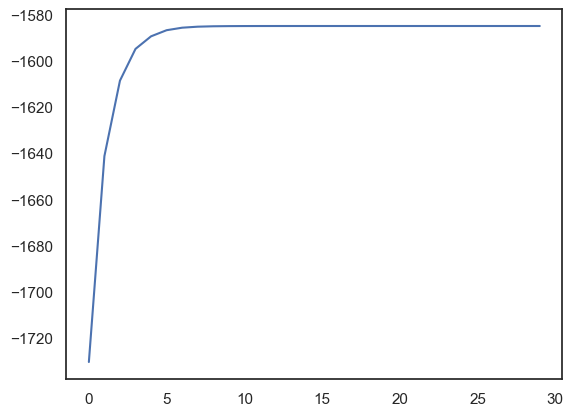

In [63]:
sns.lineplot(
    per_name_histories[
        list(per_name_histories.keys())[0]
    ].log_probabilities)

In [64]:
%%time

for i, model in enumerate(per_name_models.values()):
    print(i)
    # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
    #     model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
CPU times: total: 766 ms
Wall time: 5.87 s


In [65]:
%%time

for i, model in enumerate(per_name_models.values()):
    plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False, discrete=check_peptides, initial_params=initial_params)
    print(i)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
CPU times: total: 2min 15s
Wall time: 2min 18s


In [66]:
from hmm_visualization_methods import *


per_name_pyviz = dict()
for name, model in per_name_models.items():
    per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS, precision=3)

Converting graph for model (0_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_s_AB_s-0) (Delete zero edges)
Converting graph for model (1_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_s_AB_s-0) (Delete zero edges)
Converting graph for model (2_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_s_AB_s-0) (Delete zero edges)
Converting graph for model (3_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_s_AB_s-0) (Delete zero edges)
Converting graph for model (4_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_s_AB_s-0) (Delete zero edges)
Converting graph for model (5_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_s_AB_s-0) (Delete zero edges)
Converting graph for model (6_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_s_AB_s-0) (Delete zero edges)
Converting graph for model (7_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_s_AB_s-0) (Del

## Training steps

In [ ]:

params['st'] = 21
params['multiple_check_input'] = False
params['alg'] = algorithm
params['min_iters'] = 30
params['max_iters'] = 65
params['stop_threshold'] = stop_threshold
params['emission_pseudocount'] = 1
params['transition_pseudocount'] = 1
params['verbose'] = True
params['lr_decay'] = 0.9
params['edge_inertia'] = 0.4
params['distribution_inertia'] = 0.4
params['groups'] = 7
params['states_per_group'] = 3
params['model_complexity'] = 3
params['use_pseudocount'] = True

# Class 1 params
params['self_cycle'] = False
params['start_cycle'] = True
params['end_cycle'] = True
params['equal_probs_for_cycle'] = False

params['freeze_distr'] = False # wether to freeze start and end cycle distributions
params['tie_cycle_states'] = False
params['cycle_pseudocount'] = 300

In [234]:
allele_name = ALLELES[0]
per_kfold_per_length_train_data = per_allele_per_kfold_per_length_binders_train[allele_name]
per_kfold_per_length_test_data = per_allele_per_kfold_per_length_binders_test[allele_name]
per_kfold_per_length_weights_for_data = per_allele_per_kfold_per_length_weights[allele_name]
split_num = 0
target_lengths = TARGET_LENGTHS
per_length_current_weights = per_kfold_per_length_weights_for_data[split_num]
per_length_data = per_kfold_per_length_train_data[split_num]

per_length_test_data = per_kfold_per_length_test_data[split_num]
per_length_counts = {target_length: len(per_length_data[target_length]) for target_length in target_lengths}

# list_of_arrays = [per_length_data[target_length] for target_length in target_lengths]
# list_of_arrays_for_weights = [np.array(per_length_current_weights[target_length]) for target_length in
#                               target_lengths]
# list_of_test_arrays = [per_length_test_data[target_length] for target_length in target_lengths]
# binders_array = np.concatenate(list_of_arrays)
# weights_array = np.concatenate(list_of_arrays_for_weights)
#
# binders_test_array = np.concatenate(list_of_test_arrays)

binders_array = np.array([per_length_data[target_length][i] for target_length in target_lengths
                          for i in range(len(per_length_data[target_length]))], dtype=object)
weights_array = np.array([per_length_current_weights[target_length][i] for target_length in target_lengths
                          for i in range(len(per_length_current_weights[target_length]))], dtype=object)

binders_test_array = np.array([per_length_test_data[target_length][i] for target_length in target_lengths
                               for i in range(len(per_length_test_data[target_length]))], dtype=object)
print("split {}".format(split_num))
print("train size {}".format(len(binders_array)))
# total_length = len(binders_array)
#  weights = [1 - per_length_counts[len(peptide)]/total_length for peptide in binders_array]
# print("weights for lengths {}".format({key: 1 - value/total_length for key, value in per_length_counts.items()}))
print("Shuffling for fairness ")

rng = np.random.default_rng()
# shuffle train data and weights in unison
new_indexes = rng.permutation(len(binders_array))
binders_array = binders_array[new_indexes]
weights_array = weights_array[new_indexes]

# just shuffle test data
rng.shuffle(binders_test_array)
sample_X = np.array([[char for char in item] for item in binders_array], dtype=object)
sample_X_test = np.array([[char for char in item] for item in binders_test_array], dtype=object)

split 0
train size 5640
Shuffling for fairness 


In [235]:

sequence_generator = sample_X
sequence_test_generator = SequenceGenerator(sample_X_test)
data_generator = sequence_generator


In [236]:
data_generator = SequenceGenerator(sample_X, weights_array)

In [237]:
batches = [batch for batch in data_generator.batches()]

In [238]:
len(batches)

5640

In [239]:
from hmm_visualization_methods import *

model_to_train = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
    freeze_distr=params['freeze_distr'],
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    discrete_distribution=check_peptides,
    equal_probs_for_cycle=params['equal_probs_for_cycle'],
    tie_cycle_states=params['tie_cycle_states']
)
with open('model.png', 'w+') as f:
    model_to_train.plot(file=f, crop_zero=True, rotation=90, rotate=90)
    
    
def step(iteration):
    print(iteration)
    list_of_summaries = list()
    result = 0
    batch_size = len(binders_array)
    for set_num in range(1):
        cur_batch = batches[set_num*batch_size:(set_num+1)*batch_size]
        epoch_probs = list()
        for i, batch in enumerate(cur_batch):
            seq, weights = batch

            result += model_to_train.summarize(seq, weights, algorithm='viterbi')

        total_summaries = [state.distribution.summaries.copy() for state in model_to_train.states if state.distribution is not None]
        result_summaries[f"{iteration}_{set_num}"] = total_summaries


            # print(list_of_summaries[-1])
        step_size = None
        pseudocount = None
        transition_pseudocount = params['transition_pseudocount']
        emission_pseudocount = params['emission_pseudocount']
        use_pseudocount = params['use_pseudocount']
        edge_inertia = params['edge_inertia']
        distribution_inertia = params['distribution_inertia']

    #         new_edge_inertia = None if edge_inertia is None else 1 - ((1 - edge_inertia) * (2 + iteration) ** -params['lr_decay'])
    #         new_dist_inertia = None if edge_inertia is None else 1 - ((1 - distribution_inertia) * (2 + iteration) ** -params['lr_decay'])





        #  inertia=None, pseudocount=None,
        # transition_pseudocount=0.0, emission_pseudocount=0.0,
        # use_pseudocount=False, edge_inertia=0.0, distribution_inertia=0.0)


        model_to_train.from_summaries(inertia=step_size, 
                             pseudocount=pseudocount, 
                             transition_pseudocount=transition_pseudocount,
                             emission_pseudocount= emission_pseudocount,
                             use_pseudocount= use_pseudocount,
                             edge_inertia = edge_inertia, 
                             distribution_inertia=distribution_inertia)
        model_to_train.clear_summaries()
        model_to_train.update_transitions()
    probs.append(result)
    
    
    

result_summaries = dict()
iterations = 50
probs = list()
for iteration in range(iterations):
    step(iteration)
    
   



    # plot_distributions_for_states(prepared_model,f"test{it}/", horizontal=False, discrete=check_peptides, initial_params=initial_params)
    # make_pyviz_graph(prepared_model, f"test{it}/", precision=3)

states will be groups:21 + joiners:6 + start/end cycles:6
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49


In [240]:
iter_num = 49
batch_num = 0

l = [item[0] for item in result_summaries[f"{iter_num}_{batch_num}"]]
df  = pd.DataFrame.from_dict(l, orient='columns')
df['Total']= df.sum(axis=1)
df

,A,C,D,E,F,G,H,I,K,L,...,N,P,Q,R,S,T,V,W,Y,Total
0,0.000000,0.000000,3154.931173,1634.888240,945.047684,0.000000,0.000000,0.000000,0.000000,0.000000,...,3317.175781,6564.149149,0.000000,0.000000,578.135178,0.000000,1725.741642,0.000000,0.000000,18139.689329
1,0.000000,1664.302803,0.000000,0.000000,0.000000,0.000000,4885.335103,0.000000,1130.727736,1206.440075,...,0.000000,0.000000,0.000000,121.669545,0.000000,1105.397523,0.000000,2708.876806,0.000000,12822.749591
2,791.929525,0.000000,0.000000,0.000000,0.000000,796.691896,0.000000,3043.227910,0.000000,0.000000,...,0.000000,0.000000,327.585029,0.000000,0.000000,0.000000,0.000000,0.000000,3558.126719,8517.561079
3,0.000000,1408.978334,0.000000,0.000000,419.769897,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,867.633055,45.717265,70.684734,12998.677253,15811.460538
4,570.524815,0.000000,0.000000,0.000000,0.000000,0.000000,1277.508123,0.000000,0.000000,0.000000,...,0.000000,2572.393420,68.194350,190.748618,2168.811238,0.000000,0.000000,0.000000,0.000000,6848.180564
5,0.000000,0.000000,2450.620562,859.955422,0.000000,134.654410,0.000000,0.000000,2785.511875,5814.913647,...,3314.629871,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,16820.358898
6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,396.573779,342.405271,...,0.000000,0.000000,0.000000,0.000000,275.626754,2017.906569,0.000000,954.225020,0.000000,3986.737393
7,141.779037,0.000000,0.000000,6130.960205,1699.624714,1802.950333,0.000000,0.000000,0.000000,0.000000,...,0.000000,3578.263057,0.000000,74.098713,0.000000,0.000000,391.421108,0.000000,3273.719228,17092.816394
8,0.000000,3548.947586,3406.757295,0.000000,0.000000,0.000000,3130.249532,3296.297013,0.000000,0.000000,...,2977.087087,0.000000,1025.309281,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18667.485941
9,0.000000,0.000000,0.000000,7030.193371,2905.388769,3834.492241,4832.858634,0.000000,0.000000,0.000000,...,0.000000,3665.263742,0.000000,0.000000,0.000000,0.000000,135.518705,0.000000,0.000000,22403.715461


In [241]:
peptide = "".join(batches[2700][0][0])

In [34]:
[item[1].name for item in model_to_train.viterbi(peptide)[1]]

['grouped_model-start',
 's027',
 's027',
 's027',
 's027',
 's021',
 's000',
 's004',
 's006',
 's009',
 's013',
 's017',
 's020',
 's026',
 's031',
 's031',
 's031',
 's031',
 's031',
 's031',
 'grouped_model-end']

In [35]:
pd.DataFrame(model_to_train.backward(peptide))

,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,-59.202336,-58.855399,-58.984566,-57.867649,-58.260476,-57.829876,-63.302314,-63.454178,-63.537431,-59.626905,...,-84.568001,-59.025789,-51.567622,-53.625446,-54.416348,-84.813867,-59.267263,-58.237746,-51.873672,-inf
1,-58.036613,-57.767035,-59.089318,-54.804866,-55.197196,-54.767783,-55.743951,-55.439733,-55.662311,-61.119696,...,-81.631236,-55.814071,-48.418127,-50.548820,-51.473632,-81.877102,-56.055544,-55.283072,-48.798895,-inf
2,-50.524922,-50.188519,-50.326253,-51.862235,-52.253310,-51.816765,-51.544004,-51.237747,-51.461069,-50.869938,...,-77.478493,-51.418326,-43.990814,-50.313803,-51.614642,-77.724360,-51.659799,-51.678551,-44.392764,-inf
3,-44.624449,-44.770778,-44.563056,-46.340072,-45.640404,-46.302538,-49.674564,-49.772801,-49.574636,-49.379591,...,-74.262874,-48.202235,-40.840026,-47.594290,-46.691465,-74.508740,-48.443708,-48.657037,-41.241789,-inf
4,-46.033762,-45.769310,-47.097459,-43.256284,-43.648758,-43.219216,-43.506998,-43.632249,-43.496063,-46.140992,...,-71.182259,-45.139985,-38.402361,-41.456395,-44.729665,-71.428126,-45.381459,-45.549120,-40.644411,-inf
5,-42.791580,-41.723594,-41.791332,-39.943982,-40.336971,-39.906659,-39.958934,-40.084332,-39.947845,-40.035354,...,-67.532430,-41.772402,-40.151418,-38.169140,-43.473888,-67.778297,-42.013875,-42.009870,-40.230907,-inf
6,-31.906948,-32.053322,-31.845516,-38.728122,-38.314594,-38.538346,-37.848953,-37.973649,-37.836519,-37.833944,...,-64.419044,-39.172569,-45.690330,-39.844878,-40.411936,-64.664911,-39.414042,-38.834059,-41.419234,-inf
7,-32.671433,-32.817798,-32.610014,-31.632250,-30.931162,-31.595655,-36.181254,-36.218564,-35.898087,-34.315424,...,-61.338430,-36.110319,-43.377819,-40.542989,-38.878416,-61.584296,-36.351792,-35.726142,-40.211392,-inf
8,-33.916396,-33.648287,-35.009745,-31.871121,-31.695675,-31.947574,-28.797755,-28.923053,-28.786320,-32.647770,...,-58.257815,-33.048069,-40.945624,-36.072827,-36.874470,-58.503682,-33.289543,-32.618224,-37.234575,-inf
9,-34.020269,-33.683449,-33.815074,-30.541354,-30.933960,-30.504113,-29.993745,-29.687534,-29.910789,-27.166113,...,-55.294294,-30.071503,-37.902755,-34.344652,-34.686795,-55.540160,-30.312976,-29.220138,-35.000537,-inf


In [36]:
pd.DataFrame(model_to_train.forward(peptide))

,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,0.0,-inf
1,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-3.552433,-3.932935,-4.389121,-inf,-inf,-inf,-inf,-inf
2,-10.158809,-15.897694,-15.810694,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-7.981832,-8.640405,-8.577014,-inf,-inf,-inf,-inf,-inf
3,-18.520494,-18.492132,-9.686025,-14.357839,-21.035396,-20.918962,-inf,-inf,-inf,-inf,...,-inf,-inf,-11.132996,-11.360026,-13.500908,-inf,-inf,-inf,-inf,-inf
4,-13.821040,-22.238526,-22.244805,-20.598544,-10.600164,-21.545816,-17.189082,-25.386291,-25.009141,-inf,...,-inf,-inf,-13.570662,-22.535463,-15.540711,-inf,-inf,-inf,-inf,-inf
5,-25.683296,-17.214488,-25.689419,-24.943724,-24.703695,-19.951933,-21.355678,-21.455737,-14.302557,-20.661734,...,-inf,-inf,-16.826433,-25.841172,-18.791207,-inf,-inf,-inf,-inf,-inf
6,-20.072589,-28.342885,-28.347515,-20.933955,-28.243451,-27.711580,-30.710080,-30.967789,-22.010186,-16.415207,...,-inf,-inf,-20.025921,-28.494063,-21.995544,-inf,-inf,-inf,-inf,-inf
7,-24.305461,-32.720046,-32.725015,-31.203886,-21.047817,-30.837012,-23.765531,-31.963276,-31.585939,-25.533175,...,-inf,-inf,-22.463587,-39.669500,-24.035347,-inf,-inf,-inf,-inf,-inf
8,-29.397198,-37.936168,-37.796512,-35.427817,-25.280869,-35.059837,-23.181455,-31.903334,-32.094534,-27.299629,...,-inf,-inf,-24.901252,-50.844937,-26.075150,-inf,-inf,-inf,-inf,-inf
9,-39.868074,-32.568935,-39.851077,-40.507428,-40.279867,-32.784701,-36.036364,-27.285366,-36.323392,-24.813025,...,-30.387518,-39.243253,-27.951613,-53.450814,-28.955287,-inf,-inf,-inf,-inf,-32.476332


<AxesSubplot: >

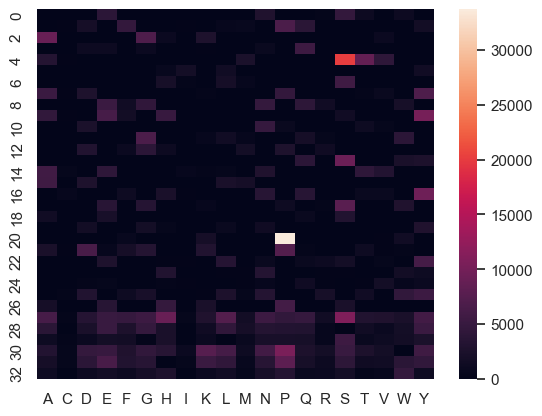

In [37]:
import seaborn as sns
sns.heatmap(df[df.columns[:-1]])

In [38]:
plot_distributions_for_states(model_to_train,f"test{iteration}/", horizontal=False, discrete=check_peptides, initial_params=initial_params)
make_pyviz_graph(model_to_train, f"test{iteration}/", precision=3)

with open(f"test{iteration}/model.png", 'w+') as f:
    model_to_train.plot(file=f, crop_zero=True, rotation=90, rotate=90)

Converting graph for model (grouped_model) (Delete zero edges)


In [39]:
model_to_train.dense_transition_matrix()[27]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.29725928, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.70274072, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ])

<AxesSubplot: >

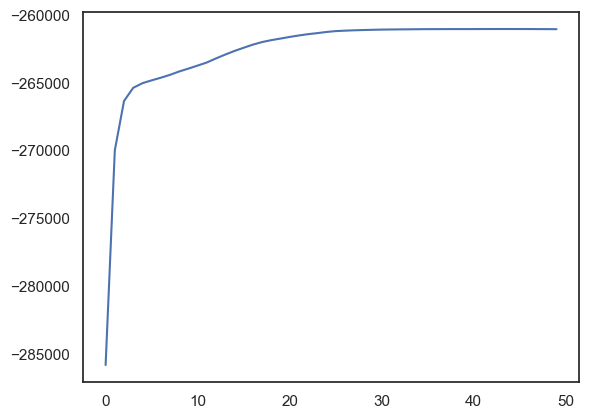

In [40]:
import seaborn as sns

sns.lineplot(probs)

In [41]:
total_summaries = [state.distribution.summaries.copy() for state in model_to_train.states if state.distribution is not None]


In [1059]:
f"test{it}/"

'test0/'